# Results of the replication: Attention Factors for Statistical Arbitrage

Epstein, Wang, Choi and Pelger (2025), *Attention Factors for Statistical Arbitrage*, ICAIF '25,
[doi:10.1145/3768292.3770398](https://doi.org/10.1145/3768292.3770398), arXiv:2510.11616.

This notebook shows the main results of the replication **from the committed result files only**
(`results/runs/<name>/metrics.json` and `daily.csv`): no WRDS data and no training are needed.
The numbers are those of round 1, the ones on the slides; `RESULTS.md` explains them in full,
and `DIFFERENCES.md` and `README_ISSUES.md` describe the later rounds.

All results are out of sample, January 1998 to December 2021, annualized, at a gross exposure of
one. "Net" means after the paper's trading costs: 5 basis points per unit traded and 1 basis point
per unit held short.

To run it: start Jupyter in `replication/` (`jupyter lab`) and open `notebooks/results.ipynb`.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = Path("..") / "results"        # the notebook runs from replication/notebooks/
RUNS = RESULTS / "runs"
assert RUNS.exists(), "start Jupyter in replication/ and open notebooks/results.ipynb"
pd.options.display.float_format = "{:.2f}".format


def metrics(name, folder=RUNS):
    """Annualized performance of one run, as saved by scripts/run.py."""
    return json.loads((folder / name / "metrics.json").read_text())


def mean_of(names, folder=RUNS):
    """Average of the metrics over the seeds of one model."""
    keys = ["SR", "mu", "sigma", "SR_net", "mu_net", "turnover_per_day"]
    return pd.DataFrame([{k: metrics(n, folder)[k] for k in keys} for n in names]).mean()


def daily(name):
    """Daily returns of one run: gross, net of costs, turnover, short exposure, market."""
    return pd.read_csv(RUNS / name / "daily.csv", parse_dates=["date"]).set_index("date")


def sharpe(x):
    return x.mean() / x.std(ddof=1) * np.sqrt(252)

## 1. Table 2 of the paper, beside the replication (30 factors)

Three models: the paper's **Attention Factor model** (factors and trading policy trained together,
with the costs in the loss), the **baseline** of the talk (PCA factors, then the same long
convolution trading policy), and the classical **PCA with an OU threshold rule**. The paper's
numbers are from its Table 2.

In [2]:
PAPER_K30 = {  # Table 2 of the paper, 30 factors: Sharpe ratio, volatility %, net Sharpe ratio
    "Attention Factor model": (3.97, 4.20, 2.28),
    "PCA + long convolution (baseline)": (2.79, 5.42, 1.57),
    "PCA + OU threshold rule": (0.18, 2.24, -6.45),
}
OURS_K30 = {
    "Attention Factor model": ["attention_K30_seed0", "attention_K30_seed1"],
    "PCA + long convolution (baseline)": ["pca_K30_seed0", "pca_K30_seed1"],
    "PCA + OU threshold rule": ["ou_K30"],
}
rows = []
for model, names in OURS_K30.items():
    m, p = mean_of(names), PAPER_K30[model]
    rows.append({"model": model, "Sharpe": m.SR, "Sharpe, paper": p[0],
                 "vol %": m.sigma, "vol %, paper": p[1],
                 "net Sharpe": m.SR_net, "net Sharpe, paper": p[2],
                 "turnover/day": m.turnover_per_day, "seeds": len(names)})
pd.DataFrame(rows).set_index("model")

,Sharpe,"Sharpe, paper",vol %,"vol %, paper",net Sharpe,"net Sharpe, paper",turnover/day,seeds
model,,,,,,,,
Attention Factor model,3.00,3.97,4.26,4.20,0.99,2.28,0.59,2
PCA + long convolution (baseline),3.47,2.79,3.21,5.42,1.26,1.57,0.47,2
PCA + OU threshold rule,1.31,0.18,2.53,2.24,-3.95,-6.45,0.96,1


**Reading.** Before costs the level of the paper reproduces in part: a Sharpe ratio of 3.00
against 3.97, about three quarters, with the same volatility (4.26 against 4.20 percent). The
ranking does not reproduce with this baseline: the baseline has the higher Sharpe ratio, because
its volatility is lower. After costs the two trained models cannot be told apart (a bootstrap is
in `results/comparison.md`). The OU rule trades about its whole book every day and loses after
costs, as in the paper.

## 2. After costs, almost all of the profit is earned before 2003

Running sums of the daily returns, in percent of the gross exposure (not compounded).

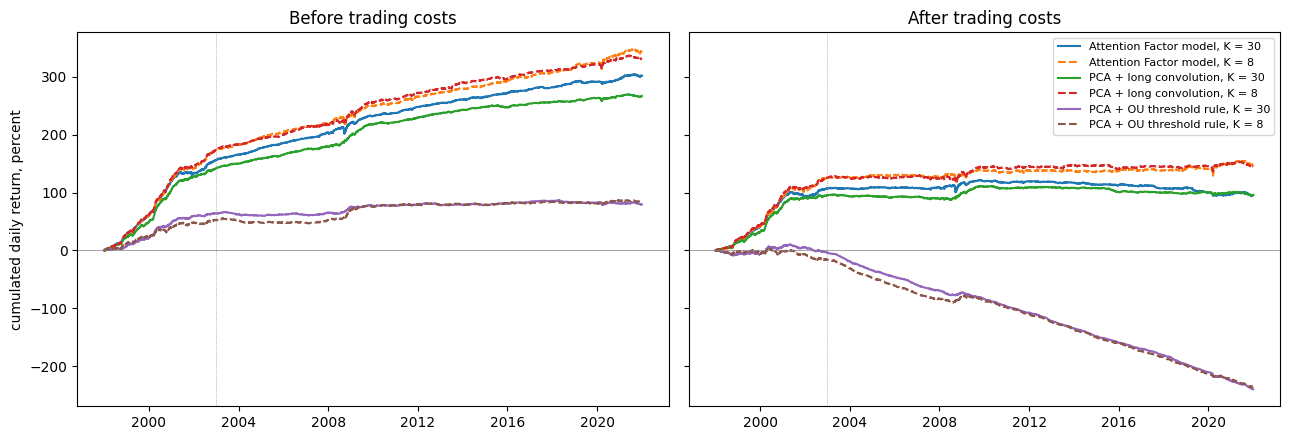

In [3]:
CURVES = {
    "Attention Factor model, K = 30": "attention_K30_seed0",
    "Attention Factor model, K = 8": "attention_K8_seed0",
    "PCA + long convolution, K = 30": "pca_K30_seed0",
    "PCA + long convolution, K = 8": "pca_K8_seed0",
    "PCA + OU threshold rule, K = 30": "ou_K30",
    "PCA + OU threshold rule, K = 8": "ou_K8",
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for label, name in CURVES.items():
    d = daily(name)
    style = "--" if "K = 8" in label else "-"
    for ax, col in zip(axes, ["gross", "net"]):
        ax.plot(d.index, d[col].cumsum() * 100, style, label=label)
axes[0].set_title("Before trading costs")
axes[1].set_title("After trading costs")
axes[0].set_ylabel("cumulated daily return, percent")
for ax in axes:
    ax.axhline(0, color="grey", lw=0.5)
    ax.axvline(pd.Timestamp("2003-01-01"), color="grey", lw=0.5, ls=":")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [4]:
PERIODS = {"1998-2002": ("1998", "2002"), "2003-2009": ("2003", "2009"),
           "2010-2021": ("2010", "2021"), "2003-2021": ("2003", "2021")}
table = {label: {p: sharpe(daily(name)["net"].loc[a:b]) for p, (a, b) in PERIODS.items()}
         for label, name in CURVES.items() if "OU" not in label}
print("Net Sharpe ratio by subperiod")
pd.DataFrame(table).T

Net Sharpe ratio by subperiod


,1998-2002,2003-2009,2010-2021,2003-2021
"Attention Factor model, K = 30",3.90,0.39,-0.61,-0.16
"Attention Factor model, K = 8",3.86,0.30,0.19,0.23
"PCA + long convolution, K = 30",4.15,0.68,-0.50,0.02
"PCA + long convolution, K = 8",4.24,0.53,0.06,0.27


**Reading.** In 1998 to 2002 every trained run has a net Sharpe ratio near 4. From 2003 on the
runs with 30 factors earn nothing after costs, and those with 8 factors little. The paper reports
no result by subperiod; the growth of its own cumulative-return figure also slows sharply after
2002 (see the critique section of the slides).

## 3. The ranking depends on how the baseline is built

The paper's benchmark section says only "PCA using the past 252 trading days"; its method section
(3.1) describes PCA factors as eigenvectors of the return **covariance** matrix, the construction of
the reported baseline. Avellaneda and Lee (2010) use the **correlation** matrix instead: returns are
first scaled to the same volatility, the factor weights are the eigenvectors divided by each
stock's volatility, and the loadings are those of a regression. The two "current history" rows
build the 30-day residual history from the factor model of the decision date instead of each
day's own.

In [5]:
BASELINES = {
    "Attention Factor model": (["attention_K30_seed0", "attention_K30_seed1"], 3.97, 2.28),
    "baseline, covariance matrix": (["pca_K30_seed0", "pca_K30_seed1"], 2.79, 1.57),
    "baseline, covariance matrix, current history": (["pca_K30_look-current_seed0"], None, None),
    "baseline, correlation matrix": (["pca_K30_corr_seed0"], 2.79, 1.57),
    "baseline, correlation matrix, current history": (["pca_K30_corr_look-current_seed0"], None, None),
}
rows = []
for label, (names, p_sr, p_net) in BASELINES.items():
    m = mean_of(names)
    rows.append({"model, 30 factors": label, "Sharpe": m.SR, "Sharpe, paper": p_sr,
                 "vol %": m.sigma, "net Sharpe": m.SR_net, "net Sharpe, paper": p_net,
                 "seeds": len(names)})
pd.DataFrame(rows).set_index("model, 30 factors")

,Sharpe,"Sharpe, paper",vol %,net Sharpe,"net Sharpe, paper",seeds
"model, 30 factors",,,,,,
Attention Factor model,3.00,3.97,4.26,0.99,2.28,2
"baseline, covariance matrix",3.47,2.79,3.21,1.26,1.57,2
"baseline, covariance matrix, current history",3.52,NaN,3.24,1.33,NaN,1
"baseline, correlation matrix",2.62,2.79,3.50,0.38,1.57,1
"baseline, correlation matrix, current history",2.63,NaN,3.57,0.43,NaN,1


In [6]:
def gap_se(a, b, block=21, draws=1000, seed=0):
    """Standard error of sharpe(a) - sharpe(b) from a circular block bootstrap of the same days."""
    rng = np.random.default_rng(seed)
    n = len(a)
    out = []
    for _ in range(draws):
        idx = ((rng.integers(0, n, -(-n // block))[:, None] + np.arange(block)) % n).ravel()[:n]
        out.append(sharpe(a[idx]) - sharpe(b[idx]))
    return np.std(out, ddof=1)


model = daily("attention_K30_seed0")["net"].to_numpy()
for label, name in [("covariance", "pca_K30_seed0"), ("correlation", "pca_K30_corr_seed0")]:
    base = daily(name)["net"].to_numpy()
    gap = sharpe(model) - sharpe(base)
    se = gap_se(model, base)
    print(f"net Sharpe, model (seed 0) minus baseline from the {label} matrix: {gap:+.2f} "
          f"(standard error {se:.2f}, {gap / se:+.1f} standard errors; blocks of 21 days)")

net Sharpe, model (seed 0) minus baseline from the covariance matrix: -0.32 (standard error 0.25, -1.3 standard errors; blocks of 21 days)


net Sharpe, model (seed 0) minus baseline from the correlation matrix: +0.56 (standard error 0.20, +2.9 standard errors; blocks of 21 days)


**Reading.** Built from the covariance matrix, as the paper describes PCA, the baseline beats
the Attention Factor model before costs, and after costs the two cannot be told apart. Built
from the correlation matrix, the baseline falls to 2.62 before costs (the paper's baseline has
2.79), and the Attention Factor model leads clearly after costs, as in the paper. Neither
construction reaches the paper's baseline volatility of 5.42 percent. How the residual history is
built changes little.

## 4. Two claims of the paper that do not reproduce

The paper's best row is the Attention Factor model with **100 factors** (Table 2), and its Table 3
says that the **past returns** drive the result: without them its net Sharpe ratio falls from
2.28 to 0.59.

In [7]:
CLAIMS = {
    "30 factors, all characteristics": (["attention_K30_seed0", "attention_K30_seed1"], 3.97, 2.28),
    "100 factors": (["attention_K100_seed0"], 4.52, 2.19),
    "30 factors, without past returns": (["attention_K30_no-past_returns_seed0"], 1.50, 0.59),
}
rows = []
for label, (names, p_sr, p_net) in CLAIMS.items():
    m = mean_of(names)
    rows.append({"Attention Factor model": label, "Sharpe": m.SR, "Sharpe, paper": p_sr,
                 "net Sharpe": m.SR_net, "net Sharpe, paper": p_net,
                 "turnover/day": m.turnover_per_day, "seeds": len(names)})
pd.DataFrame(rows).set_index("Attention Factor model")

,Sharpe,"Sharpe, paper",net Sharpe,"net Sharpe, paper",turnover/day,seeds
Attention Factor model,,,,,,
"30 factors, all characteristics",3.00,3.97,0.99,2.28,0.59,2
100 factors,3.04,4.52,0.33,2.19,0.62,1
"30 factors, without past returns",2.59,1.50,1.02,0.59,0.57,1


**Reading.** 100 factors add nothing before costs and lose after costs: the extra factors are
used (about 91 effective factors), but the portfolio trades more and the costs take most of its
return. Without the past returns the model loses a little before costs and nothing after them,
so in this replication they are not what drives the result.

## 5. The objective as printed (a later round)

The paper's objective adds the net Sharpe ratio and 100 times the explained variance. Read
literally, the Sharpe ratio is per day, a number near 0.2 beside a variance term near 40. The
reported runs annualize it (times the square root of 252), a choice made on the validation years
1996 to 1997. Round 2 refit the model with the ratio per day, on the same data and protocol.

In [8]:
rows = []
for name in ["attention_K30_seed0", "attention_K30_seed1", "attention_K8_seed0"]:
    a, p = metrics(name), metrics(name, RESULTS / "daily_sharpe")
    rows.append({"run": name, "Sharpe, annualized objective": a["SR"], "Sharpe, as printed": p["SR"],
                 "net Sharpe, annualized objective": a["SR_net"], "net Sharpe, as printed": p["SR_net"]})
pd.DataFrame(rows).set_index("run")

,"Sharpe, annualized objective","Sharpe, as printed","net Sharpe, annualized objective","net Sharpe, as printed"
run,,,,
attention_K30_seed0,2.97,2.22,0.94,0.19
attention_K30_seed1,3.04,1.99,1.03,-0.02
attention_K8_seed0,2.66,2.10,1.15,0.42


## Summary

- **Reproduced in part:** the level before costs (a Sharpe ratio of 3.00 against 3.97 with 30
  factors), and the large loss of the parametric OU rule after costs.
- **Depends on an open choice:** the ranking against the baseline. With the covariance PCA that
  the paper describes, the baseline wins; with the correlation PCA of Avellaneda and Lee, the
  Attention Factor model wins.
- **Not reproduced:** the gains from 100 factors and from the past returns, and the level after
  costs (0.99 against 2.28).
- **Soft spot:** after costs, almost all of the profit is earned before 2003.

More: `RESULTS.md` (all numbers, and "What did not work"), `DIFFERENCES.md` and `README_ISSUES.md`
(later rounds, another universe and other settings), `AI_USAGE.md` (how AI tools were used).